# 16.1 - Alignment source and box audit

Inspect the author-linked OMNI train/validation data and shortlist Roboflow OCCLSAL ORTHO AI. The target labels are upper midline diastema and anterior crowding on frontal photographs. Source test content is held out.

## Verify the archive and inspect the two development splits

The SHA-256 fingerprints the downloaded author-linked ZIP. It is a local observation. Only train and validation COCO files and image members are read.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from io import BytesIO
import json, hashlib, random, zipfile
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

root=Path.cwd()
while not (root/'pyproject.toml').exists():
    if root == root.parent:
        raise RuntimeError('Project root not found')
    root=root.parent
archive_path=root/'data/raw/alignment_omni/OMNI_COCO.zip'
expected='3ea84e0b7f28526f80b000dfd9bfdf4677f54d66e24d5a60eedfc93afe87f525'
assert hashlib.sha256(archive_path.read_bytes()).hexdigest()==expected
report=root/'docs/reports/alignment'
report.mkdir(exist_ok=True)
archive=zipfile.ZipFile(archive_path)
stats=[]; records=[]; tm_examples=[]; issues=[]; category_counts=[]
for split in ['train','val']:
    data=json.loads(archive.read(f'omni_coco/annotations/instances_{split}.json'))
    categories={r['id']:r['name'] for r in data['categories']}
    assert categories[7]=='TM'
    image_ids={im['id'] for im in data['images']}
    assert len(image_ids)==len(data['images'])
    annotations=defaultdict(list)
    for ann in data['annotations']:
        assert ann['image_id'] in image_ids and ann['category_id'] in categories
        annotations[ann['image_id']].append(ann)
    for category, count in Counter(categories[a['category_id']] for a in data['annotations']).items():
        category_counts.append((split,category,count))
    for im in data['images']:
        member=f"omni_coco/{split}/{im['subfolder1']}/{im['subfolder2']}/{im['file_name']}"
        payload=archive.read(member)
        with Image.open(BytesIO(payload)) as photo:
            if photo.size!=(im['width'],im['height']):
                issues.append((split,im['id'],None,'dimension_mismatch'))
        tm_count=0
        for ann in annotations[im['id']]:
            x,y,w,h=ann['bbox']
            if not (w>0 and h>0 and x>=0 and y>=0 and x+w<=im['width'] and y+h<=im['height']):
                issues.append((split,im['id'],ann['id'],'invalid_box'))
            if categories[ann['category_id']]=='TM':
                tm_count+=1
        records.append((split,im['id'],im['subfolder1'],im['subfolder2'],member,hashlib.sha256(payload).hexdigest(),tm_count))
        if tm_count:
            tm_examples.append((split,member,annotations[im['id']]))
    stats.append(dict(split=split,images=len(data['images']),boxes=len(data['annotations']),
                      tm_images=sum(r[-1]>0 for r in records if r[0]==split),
                      tm_boxes=sum(r[-1] for r in records if r[0]==split),license_records=len(data['licenses'])))
summary=pd.DataFrame(stats)
display(summary)
pd.DataFrame(category_counts,columns=['split','category','boxes']).to_csv(report/'omni_category_counts.csv',index=False)

,split,images,boxes,tm_images,tm_boxes,license_records
0,train,2481,36449,76,85,0
1,val,857,12482,30,42,0


## Check split overlap and metadata coverage

Compare byte-level hashes across splits and report folder-key overlap as a provenance clue. Folder keys are not verified participant identifiers. There is no explicit view field in the inspected image rows, so frontal counts in the paper are not treated as a per-image view map.

In [2]:
manifest=pd.DataFrame(records,columns=['split','source_image_id','folder_1','folder_2','archive_member','sha256','tm_boxes'])
train=manifest.query("split=='train'")
val=manifest.query("split=='val'")
cross_hashes=set(train.sha256)&set(val.sha256)
cross_folders=set(train.folder_1)&set(val.folder_1)
summary['geometry_or_dimension_flags']=[sum(r[0]==s for r in issues) for s in summary.split]
summary.to_csv(report/'omni_split_counts.csv',index=False)
manifest.to_csv(report/'omni_audit_manifest.csv',index=False)
pd.DataFrame(issues,columns=['split','source_image_id','annotation_id','reason']).to_csv(report/'omni_geometry_flags.csv',index=False)
evidence=dict(archive_sha256=expected,cross_split_exact_hashes=len(cross_hashes),
              cross_split_exact_images=int(manifest.sha256.isin(cross_hashes).sum()),
              shared_folder_1_keys=len(cross_folders),source_test_opened=False)
(report/'omni_audit_summary.json').write_text(json.dumps(evidence,indent=2))
display(summary)
print(evidence)

,split,images,boxes,tm_images,tm_boxes,license_records,geometry_or_dimension_flags
0,train,2481,36449,76,85,0,2
1,val,857,12482,30,42,0,2


{'archive_sha256': '3ea84e0b7f28526f80b000dfd9bfdf4677f54d66e24d5a60eedfc93afe87f525', 'cross_split_exact_hashes': 0, 'cross_split_exact_images': 0, 'shared_folder_1_keys': 0, 'source_test_opened': False}


## Inspect the TM boxes

View six seeded train and six validation TM-positive images. Orange boxes are source TM annotations and do not identify the separate project classes.

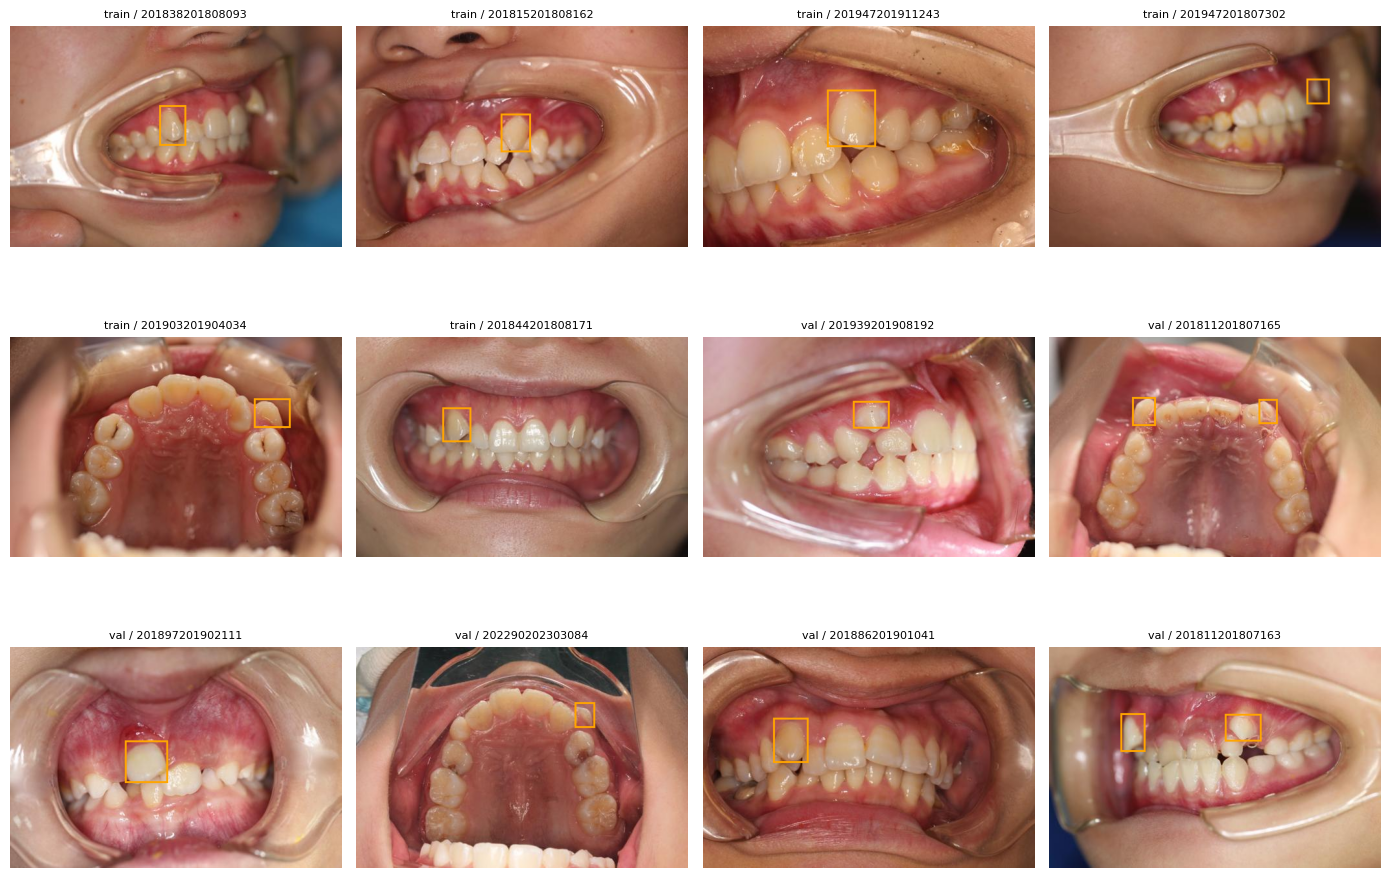

In [3]:
fig,axes=plt.subplots(3,4,figsize=(14,10))
rng=random.Random(42)
selected=[]
for split in ['train','val']:
    pool=[item for item in tm_examples if item[0]==split]
    selected.extend(rng.sample(pool,min(6,len(pool))))
for ax in axes.flat:
    ax.axis('off')
for ax,(split,member,anns) in zip(axes.flat,selected):
    with Image.open(BytesIO(archive.read(member))) as photo:
        image=photo.convert('RGB')
    draw=ImageDraw.Draw(image)
    for ann in anns:
        if ann['category_id']==7:
            x,y,w,h=ann['bbox']
            if w>0 and h>0:
                draw.rectangle((x,y,x+w,y+h),outline='orange',width=3)
    ax.imshow(image)
    ax.set_title(f'{split} / {Path(member).stem}',fontsize=8)
plt.tight_layout()
fig.savefig(report/'omni_tm_sample.png',dpi=140)
plt.show()
archive.close()